<a href="https://colab.research.google.com/github/faisalhamza909-blip/mental-health-clustering-case-study-/blob/main/mental_health_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mental Health in Tech: Clustering Employees for an HR Prevention Programme

Case study for DLBDSMLUSL01 – Machine Learning: Unsupervised Learning and Feature Engineering.
Data: OSMI Mental Health in Tech Survey 2016 (Kaggle).


In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


figures_folder = "/content/drive/MyDrive/case study/figures"
os.makedirs(figures_folder, exist_ok=True)

path = "/content/drive/MyDrive/case study/mental-heath-in-tech-2016_20161114.csv"
df = pd.read_csv(path)

figures_folder = "/content/drive/MyDrive/case study/figures"
os.makedirs(figures_folder, exist_ok=True)

## Step 1: Data exploration


### 1.1 Overview

In [52]:
df.shape

(1433, 63)

The dataset contains 1,433 respondents (rows) and 63 survey questions (columns).

In [53]:
df.head()

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                                                                                                                                                                            Non-Null Count  Dtype  
---  ------                                                                                                                                                                            --------------  -----  
 0   Are you self-employed?                                                                                                                                                            1433 non-null   int64  
 1   How many employees does your company or organization have?                                                                                                                        1146 non-null   object 
 2   Is your employer primarily a tech company/organization?     

### 1.2 Missing values
The percentage of missing answer is calculated fo each column, to see which columns may need to be dropped or handled separately

In [55]:
missing_values = df.isnull()
mean_of_missing_values = missing_values.mean()
missing_percentage = mean_of_missing_values * 100



In [56]:
missing_percentage = missing_percentage.sort_values(ascending = False)
missing_percentage.head(15).round(1)

,0
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",90.0
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",85.8
Is your primary role within your company related to tech/IT?,81.6
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,80.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",80.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",80.0
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",80.0
Do you know local or online resources to seek help for a mental health disorder?,80.0
Do you believe your productivity is ever affected by a mental health issue?,80.0
"If maybe, what condition(s) do you believe you have?",77.5


The table above shows that the columns with very high missing values are mostly caused by the survey’s conditional structure (for example, questions that were only shown to self-employed respondents). Since these values are missing because of how the survey was designed, they will be dropped or filtered later on.

In [57]:
print(f"Column with more than 50% missing values: {(missing_percentage > 50).sum()}")
print(f"Column with no missing values: {(missing_percentage == 0).sum()}")


Column with more than 50% missing values: 13
Column with no missing values: 19


### 1.3 Gender

In [58]:
gender = df["What is your gender?"]
print(f"Number of unique genders: {gender.nunique()}")
print(f"Missing values: {gender.isnull().sum()}")
gender.value_counts().head(20)


Number of unique genders: 70
Missing values: 3


,count
What is your gender?,
Male,610
male,249
Female,153
female,95
M,86
m,79
F,38
f,23
Male,11


The output shows that the gender column contains 70 different answers and 3 missing values, although many of them mean the same thing. For example, “Male”, “male” and “M” all refer to male, and some answers even contain hidden spaces.

### 1.4 Age

In [59]:
age = df["What is your age?"]
age.describe()


,What is your age?
count,1433.000000
mean,34.286113
std,11.290931
min,3.000000
25%,28.000000
50%,33.000000
75%,39.000000
max,323.000000


In [60]:
unrealistic_ages = age[(age < 16) | (age>75)]
print(f"Number of unrealistic ages : {len(unrealistic_ages)}")
print(unrealistic_ages)

Number of unrealistic ages : 4
372     99
564    323
656      3
808     15
Name: What is your age?, dtype: int64


The age column has no missing values. The median age is 33, and most respondents are between 28 and 39 years old. A few values are unrealistic (3, 15, 99 and 323) and are most likely typos or joke answers, or too young for regular employment. It is very unlikely that someone younger than 16 works in a tech company, while 17-year-olds could plausibly be interns or apprentices. Therefore, only ages between 16 and 75 are considered realistic.

### 1.5 Overview charts

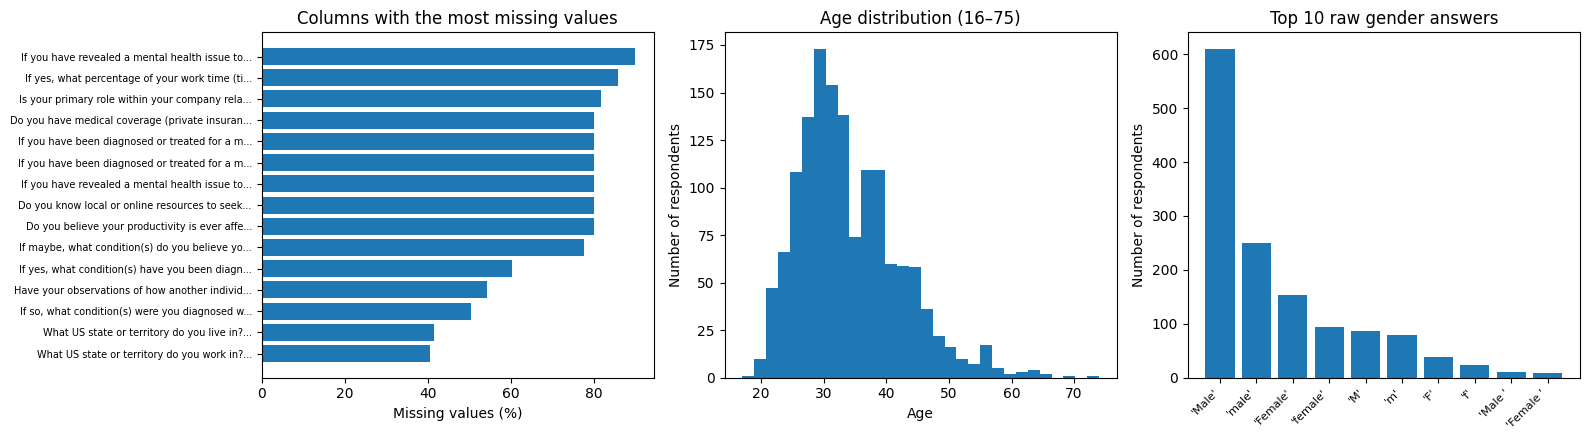

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


top_missing = (df.isnull().mean() * 100).sort_values(ascending=False).head(15)
axes[0].barh(range(len(top_missing)), top_missing.values)
axes[0].set_yticks(range(len(top_missing)))
axes[0].set_yticklabels([name[:45] + "..." for name in top_missing.index], fontsize=7)
axes[0].invert_yaxis()
axes[0].set_xlabel("Missing values (%)")
axes[0].set_title("Columns with the most missing values")


realistic = df["What is your age?"][(df["What is your age?"] >= 16) & (df["What is your age?"] <= 75)]
axes[1].hist(realistic, bins=30)
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Number of respondents")
axes[1].set_title("Age distribution (16–75)")


top_gender = df["What is your gender?"].value_counts().head(10)
axes[2].bar(range(len(top_gender)), top_gender.values)
axes[2].set_xticks(range(len(top_gender)))
axes[2].set_xticklabels([repr(g) for g in top_gender.index], rotation=45, ha="right", fontsize=8)
axes[2].set_ylabel("Number of respondents")
axes[2].set_title("Top 10 raw gender answers")

plt.tight_layout()
plt.savefig(f"{figures_folder}/exploration_overview.png", dpi=150, bbox_inches="tight")
plt.show()

The overview charts summarise the main findings of the data exploration. The missing-value chart shows that around ten columns are 80–90% empty, which is caused by the survey’s conditional structure (e.g. questions only shown to self-employed respondents). The age distribution (realistic ages only) shows that most respondents are between 25 and 45 years old, with a peak around 30, and is skewed to the right. The gender chart shows that the same answer appears in several spellings, such as “Male”, “male”, “M”, “m” and “Male “ with a hidden space, which confirms the need to standardise this column during cleaning.

### 1.6 Summary of data exploration
The dataset contains 1,433 respondents and 63 columns. The exploration revealed three main problems. Many missing values caused by the survey’s conditional structure (up to 90% in some columns), a gender column with 70 different free-text answers for essentially a few categories, and a small number of unrealistic ages (3, 15, 99 and 323). These issues are addressed in the data cleaning step.

## Step 2: Data cleaning


### 2.1 Keep only employees

In [62]:
self_employed = df['Are you self-employed?']
self_employed.value_counts()

,count
Are you self-employed?,
0,1146
1,287


In [63]:
is_employee = df['Are you self-employed?'] == 0
df_clean = df[is_employee].copy()
print(f"Rows before: {len(df)}")
print(f"Rows after: {len(df_clean)}")
print(f"self-employed: {len(df)-len(df_clean)}")


Rows before: 1433
Rows after: 1146
self-employed: 287


The dataset was filtered to employees only, because the HR programme targets the company’s employees. Self-employed respondents also could not answer the employer related questions, which caused many of the missing values. The dataset was reduced from 1,433 to 1,146 respondents.

### 2.2 Drop empty and unusable columns

In [64]:
missing_values = df_clean.isnull()
mean_of_missing_values = missing_values.mean()
missing_percentage = mean_of_missing_values * 100
missing_percentage = missing_percentage.sort_values(ascending=False)
empty_columns = missing_percentage[missing_percentage == 100]
print(f"Columns that are now 100% empty: {len(empty_columns)}")
missing_percentage[missing_percentage>0].round(1)


Columns that are now 100% empty: 8


,0
Do you believe your productivity is ever affected by a mental health issue?,100.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",100.0
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",100.0
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",100.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",100.0
Do you know local or online resources to seek help for a mental health disorder?,100.0
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,100.0
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",100.0
"If maybe, what condition(s) do you believe you have?",78.2
Is your primary role within your company related to tech/IT?,77.1


After filtering, 8 columns became 100% empty, since these questions were only shown to self-employed respondents. They contain no information for this analysis and will be dropped. Other columns still have missing values, mostly because of follow-up questions, US-only questions and optional free-text answers. In addition, 11 more columns will be dropped because they cannot be used for clustering: the self-employed column (now always 0), the tech-role question (77% missing), free-text answers, a follow-up question with 55% missing values, the US state columns and “country you live in” (largely the same as “country you work in”).

In [65]:
columns_to_drop = empty_columns.index
df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Columns before: {df.shape[1]}")
print(f"Columns after: {df_clean.shape[1]}")

Columns before: 63
Columns after: 55


In [66]:
other_columns_to_drop = [
    "Are you self-employed?",
    "Is your primary role within your company related to tech/IT?",
    "Why or why not?",
    "Why or why not?.1",
    "If maybe, what condition(s) do you believe you have?",
    "If yes, what condition(s) have you been diagnosed with?",
    "If so, what condition(s) were you diagnosed with?",
    "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?",
    "What US state or territory do you live in?",
    "What US state or territory do you work in?",
    "What country do you live in?"
    ]
print(f"Columns before: {df_clean.shape[1]}")
df_clean = df_clean.drop(columns=other_columns_to_drop)
print(f"Columns after: {df_clean.shape[1]}")


Columns before: 55
Columns after: 44


### 2.3 Clean gender

In [67]:
gender_column = "What is your gender?"
df_clean[gender_column] = df_clean[gender_column].str.strip().str.lower()
print(f"Different answers after: {df_clean[gender_column].nunique()}")
df_clean[gender_column].value_counts()


Different answers after: 47


,count
What is your gender?,
male,707
female,209
m,125
f,44
woman,6
non-binary,4
man,3
cis male,3
agender,2


In [68]:
male_answers = ["male","m","cis male","male (cis)","male.","mail","dude","cisdude",
                "cis man","man", "sex is male","male (trans, ftm)"]
female_answers = ["female","f","woman","cis female","cisgender female","cis-woman",
                  "female/woman","fem","i identify as female.","female (props for making this a freeform field, though)",
                  "transgender woman", "transitioned, m2f"]
def group_gender(answer):
  if pd.isnull(answer):
    return "unknown"
  elif answer in male_answers:
    return "male"
  elif answer in female_answers:
    return "female"
  else:
    return "other"

df_clean[gender_column] = df_clean[gender_column].apply(group_gender)
df_clean[gender_column].value_counts()

,count
What is your gender?,
male,847
female,268
other,28
unknown,3


The gender column originally contained 70 different answers. First, extra spaces were removed and all answers were converted to lower case, which reduced the number of different answers to 47. These were then grouped into four categories: male (847), female (268), other (28) and unknown (3). Trans respondents were grouped by the gender they identify with, and non-binary or unclear answers were grouped as “other” instead of being forced into male or female. The sample is strongly male-dominated (74%), which reflects the tech industry but should be kept in mind when interpreting the results.

### 2.4 Remove unrealistic ages

In [69]:
age_column = "What is your age?"
realistic_age = (df_clean[age_column]>=16) & (df_clean[age_column]<=75)
unrealistic_rows = df_clean[~realistic_age]
print(f"Removed ages: {sorted(unrealistic_rows[age_column])}")
print(f"Rows before:{len(df_clean)}")
df_clean = df_clean[realistic_age].copy()
print(f"Rows after: {len(df_clean)}")

Removed ages: [3, 99, 323]
Rows before:1146
Rows after: 1143


Three respondents with unrealistic ages (3, 99 and 323) were removed, leaving 1,143 respondents. The 15-year-old found during exploration was self-employed and had already been removed.

### 2.5 Fill remaining missing values

In [70]:
missing_count = df_clean.isnull().sum()
missing_count = missing_count[missing_count>0]
print(f"Columns with missing values: {len(missing_count)}")
missing_count

Columns with missing values: 13


,0
Do you know the options for mental health care available under your employer-provided coverage?,133
Have your previous employers provided mental health benefits?,131
Were you aware of the options for mental health care provided by your previous employers?,131
Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?,131
Did your previous employers provide resources to learn more about mental health issues and how to seek help?,131
Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?,131
Do you think that discussing a mental health disorder with previous employers would have negative consequences?,131
Do you think that discussing a physical health issue with previous employers would have negative consequences?,131
Would you have been willing to discuss a mental health issue with your previous co-workers?,131
Would you have been willing to discuss a mental health issue with your direct supervisor(s)?,131


In [71]:
previous_employer_col = "Do you have previous employers?"
df_clean[previous_employer_col].value_counts()

,count
Do you have previous employers?,
1,1012
0,131


The missing value check shows that 13 columns still have gaps. 11 of them have exactly 131 missing values each, and all of these are questions about previous employers. The second output shows that exactly 131 respondents have no previous employer, so these questions simply did not apply to them

In [72]:
previous_employer_col = missing_count[missing_count == 131].index
df_clean[previous_employer_col] = df_clean[previous_employer_col].fillna("No previous employer")
print(f"Columns filled: {len(previous_employer_col)}")
print(f"Missing values left in these columns: {df_clean[previous_employer_col].isnull().sum().sum()}")


Columns filled: 11
Missing values left in these columns: 0


The 11 previous-employer columns were filled with the category “No previous employer”. This keeps the information that these respondents had no previous employer, instead of inventing an answer for them.

In [73]:
options_col = "Do you know the options for mental health care available under your employer-provided coverage?"
benefits_col = "Does your employer provide mental health benefits as part of healthcare coverage?"
options_missing = df_clean[options_col].isnull()
df_clean.loc[options_missing, benefits_col].value_counts()


,count
Does your employer provide mental health benefits as part of healthcare coverage?,
No,72
Not eligible for coverage / N/A,55
I don't know,6


In [74]:
df_clean[options_col] = df_clean[options_col].fillna("Not applicable")
print(f"Missing values left: {df_clean[options_col].isnull().sum()}")
df_clean[options_col].value_counts()

Missing values left: 0


,count
Do you know the options for mental health care available under your employer-provided coverage?,
No,352
I am not sure,351
Yes,307
Not applicable,133


In [75]:
unsupportive_col = "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"
print(df_clean[unsupportive_col].value_counts(dropna=False))
df_clean[unsupportive_col] = df_clean[unsupportive_col].fillna("Not answered")
print(f"Missing values left: {df_clean.isnull().sum().sum()}")

Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
No                    491
Maybe/Not sure        276
Yes, I observed       193
Yes, I experienced    131
NaN                    52
Name: count, dtype: int64
Missing values left: 0


The question about knowing mental health care options had 133 missing values. All of these respondents had said that their employer provides no mental health benefits (72), that they are not eligible for coverage (55) or that they did not know (6), so the follow-up question did not apply to them, and the gaps were filled with “Not applicable”. The question about observing an unsupportive response had 52 missing values. This question was shown to everyone, so these respondents chose to skip it, and the gaps were filled with “Not answered”. To avoid inventing information, separate categories were used instead of the most common answer. The dataset now contains no missing values.

### 2.6 Rename columns

In [76]:
short_names = ["company_size", "tech_company", "mh_benefits", "knows_care_options",
    "employer_discussed_mh", "employer_mh_resources", "anonymity_protected", "ease_medical_leave",
    "mh_negative_consequences", "ph_negative_consequences", "comfortable_coworkers", "comfortable_supervisor",
    "employer_takes_mh_seriously", "observed_consequences_coworkers", "has_previous_employer",
    "prev_mh_benefits", "prev_aware_options", "prev_employer_discussed_mh", "prev_mh_resources",
    "prev_anonymity_protected", "prev_mh_negative_consequences", "prev_ph_negative_consequences",
    "prev_comfortable_coworkers", "prev_comfortable_supervisor", "prev_takes_mh_seriously",
    "prev_observed_consequences", "interview_physical", "interview_mental", "hurt_career",
    "coworkers_view_negatively", "share_with_family", "observed_unsupportive_response",
    "family_history", "past_disorder", "current_disorder", "diagnosed_professional",
    "sought_treatment", "interferes_treated", "interferes_untreated", "age", "gender",
    "country_work", "work_position", "remote_work",]
print(f"Number of columns: {df_clean.shape[1]}, number of new names: {len(short_names)}")
col_lookup = pd.DataFrame({"short_name": short_names, "original_question": df_clean.columns})
df_clean.columns = short_names
col_lookup.to_csv("/content/drive/MyDrive/case study/column_lookup.csv", index=False)
col_lookup.head(10)


Number of columns: 44, number of new names: 44


,short_name,original_question
0,company_size,How many employees does your company or organi...
1,tech_company,Is your employer primarily a tech company/orga...
2,mh_benefits,Does your employer provide mental health benef...
3,knows_care_options,Do you know the options for mental health care...
4,employer_discussed_mh,Has your employer ever formally discussed ment...
5,employer_mh_resources,Does your employer offer resources to learn mo...
6,anonymity_protected,Is your anonymity protected if you choose to t...
7,ease_medical_leave,If a mental health issue prompted you to reque...
8,mh_negative_consequences,Do you think that discussing a mental health d...
9,ph_negative_consequences,Do you think that discussing a physical health...


The 44 columns were renamed from full survey questions to short names (e.g. “mh_benefits” for “Does your employer provide mental health benefits as part of healthcare coverage?”) to make the following steps and plots readable. A lookup table linking each short name to its original question was saved as column_lookup.csv.

In [77]:
print(f"Final shape: {df_clean.shape}")
print(f"Final missing values: {df_clean.isnull().sum().sum()}")

Final shape: (1143, 44)
Final missing values: 0


### 2.7 Summary of data cleaning
The dataset was reduced from 1,433 respondents and 63 columns to 1,143 employees and 44 columns. Self-employed respondents were removed, empty and unusable columns were dropped, gender answers were grouped into four categories, three unrealistic ages were removed, and all remaining missing values were filled with meaningful categories. The data is now clean and ready for encoding.

## Step 3: Encoding and scaling


### 3.1 Answer types per column

In [78]:
for column in df_clean.columns:
  answer = df_clean[column]
  unique_answers = answer.unique()
  print(f"{column}: {len(unique_answers)} options: {unique_answers[:8]}")

company_size: 6 options: ['26-100' '6-25' 'More than 1000' '100-500' '500-1000' '1-5']
tech_company: 2 options: [1. 0.]
mh_benefits: 4 options: ['Not eligible for coverage / N/A' 'No' 'Yes' "I don't know"]
knows_care_options: 4 options: ['Not applicable' 'Yes' 'I am not sure' 'No']
employer_discussed_mh: 3 options: ['No' 'Yes' "I don't know"]
employer_mh_resources: 3 options: ['No' 'Yes' "I don't know"]
anonymity_protected: 3 options: ["I don't know" 'Yes' 'No']
ease_medical_leave: 6 options: ['Very easy' 'Somewhat easy' 'Neither easy nor difficult' 'Very difficult'
 'Somewhat difficult' "I don't know"]
mh_negative_consequences: 3 options: ['No' 'Maybe' 'Yes']
ph_negative_consequences: 3 options: ['No' 'Maybe' 'Yes']
comfortable_coworkers: 3 options: ['Maybe' 'Yes' 'No']
comfortable_supervisor: 3 options: ['Yes' 'Maybe' 'No']
employer_takes_mh_seriously: 3 options: ["I don't know" 'Yes' 'No']
observed_consequences_coworkers: 2 options: ['No' 'Yes']
has_previous_employer: 2 options: [1 

Four columns are already numeric. Two columns have a clear order without extra categories and will be encoded as ordinal numbers. Most other columns are survey answers that often include options like “I don’t know”, “Not applicable” or “No previous employer”, which do not fit on an ordered scale, so they will be one-hot encoded. Two columns need special handling: country, with 44 different countries, and work position, with 180 different combinations.

### 3.2 Ordinal encoding

In [79]:
df_encoded = df_clean.copy()

company_size_order = {
     "1-5": 0,
    "6-25": 1,
    "26-100": 2,
    "100-500": 3,
    "500-1000": 4,
    "More than 1000": 5,
}

remote_work_order = {
    "Never": 0,
    "Sometimes": 1,
    "Always": 2,
}
df_encoded["company_size"] = df_encoded["company_size"].map(company_size_order)
df_encoded["remote_work"] = df_encoded["remote_work"].map(remote_work_order)
print(f"Missing after encoding: {df_encoded[['company_size','remote_work']].isnull().sum().sum()}")

Missing after encoding: 0


Company size and remote work have a clear natural order, so they were encoded as ordinal numbers: company size from 0 (1–5 employees) to 5 (more than 1,000 employees), and remote work from 0 (never) to 2 (always). This keeps the order information, so that larger differences in the original answers also mean larger differences in the numbers.

### 3.3 Country grouping

In [80]:
country_counts = df_encoded["country_work"].value_counts()
print(f"Number of countries: {len(country_counts)}")
country_counts.head(12)

Number of countries: 44


,count
country_work,
United States of America,714
United Kingdom,133
Canada,60
Germany,44
Netherlands,31
Australia,26
Sweden,15
France,11
Ireland,10


The respondents work in 44 different countries, but the data is heavily US-based (714 of 1,143, about 62%). Only six countries have more than 25 respondents, while the other 38 countries have between 1 and 15 respondents each, which would create many almost empty columns after one-hot encoding.

In [81]:
#big countries = at least 25 respondents
big_countries = country_counts[country_counts>=25].index
print(f"Countries kept: {list(big_countries)}")

def group_country(country):
  if country in big_countries:
    return country
  else:
    return "Other"

df_encoded["country_work"] = df_encoded["country_work"].apply(group_country)
df_encoded["country_work"].value_counts()



Countries kept: ['United States of America', 'United Kingdom', 'Canada', 'Germany', 'Netherlands', 'Australia']


,count
country_work,
United States of America,714
Other,135
United Kingdom,133
Canada,60
Germany,44
Netherlands,31
Australia,26


To avoid many almost empty columns, only countries with at least 25 respondents were kept as separate categories (United States, United Kingdom, Canada, Germany, Netherlands and Australia), and the remaining 38 countries were grouped as “Other” (135 respondents). This reduces the country column from 44 to 7 categories while still covering the main countries, which make up around 88% of the data.

### 3.4 Work position roles

In [82]:
roles = df_encoded["work_position"].str.get_dummies(sep="|")
print(roles.sum().sort_values(ascending=False))
roles = roles.add_prefix("role_")
df_encoded = df_encoded.drop(columns = "work_position")
df_encoded = df_encoded.join(roles)
df_encoded.shape

Back-end Developer         599
Front-end Developer        399
Supervisor/Team Lead       227
DevOps/SysAdmin            223
Other                      148
Support                    127
Designer                    89
Dev Evangelist/Advocate     82
Executive Leadership        59
One-person shop             23
Sales                       11
HR                          10
dtype: int64


(1143, 55)

The work position column contained 180 different combinations, because respondents could select several roles (e.g. “Back-end Developer|Front-end Developer”). It was split into 12 separate 0/1 columns, one per role. This way, respondents who share a role are recognised as similar, even if they also selected other roles. The dataset now has 55 columns.

### 3.5 One-hot encoding

In [83]:
text_col = df_encoded.select_dtypes(exclude="number").columns
print(f"Text columns to encode : {len(text_col)}")

df_encoded = pd.get_dummies(df_encoded, columns = text_col, dtype = int)
print(df_encoded.shape)
df_encoded.head()

Text columns to encode : 37
(1143, 168)


,company_size,tech_company,has_previous_employer,sought_treatment,age,remote_work,role_Back-end Developer,role_Designer,role_Dev Evangelist/Advocate,role_DevOps/SysAdmin,...,gender_male,gender_other,gender_unknown,country_work_Australia,country_work_Canada,country_work_Germany,country_work_Netherlands,country_work_Other,country_work_United Kingdom,country_work_United States of America
0,2,1.0,1,0,39,1,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
1,1,1.0,1,1,29,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,1
2,1,1.0,1,1,38,2,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
4,1,0.0,1,1,43,1,1,0,1,1,...,0,0,0,0,0,0,0,0,0,1
5,5,1.0,1,1,42,1,1,1,0,1,...,1,0,0,0,0,0,0,0,1,0


The remaining 37 text columns were one-hot encoded, so that each answer option became its own 0/1 column. After encoding, the dataset consists only of numbers and has 168 columns. This high number of dimensions is typical for survey data and will be reduced later with PCA.

### 3.6 Scaling
The columns are on very different scales. For example, a 20-year age difference would count as 20, while a different answer to a question like “Does your employer offer mental health benefits?” counts as only 1, so age would dominate the distance calculations just because its numbers are bigger. To fix this, every column is rescaled so that its mean is 0 and its standard deviation is 1, so that every column has the same weight.

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)
df_scaled = pd.DataFrame(df_scaled, columns = df_encoded.columns, index = df_encoded.index)
print(df_scaled.shape)
print(f"Average of age after scaling: {df_scaled['age'].mean():.2f}")
print(f"Spread of age after scaling: {df_scaled['age'].std():.2f}")
df_scaled.head()

(1143, 168)
Average of age after scaling: -0.00
Spread of age after scaling: 1.00


,company_size,tech_company,has_previous_employer,sought_treatment,age,remote_work,role_Back-end Developer,role_Designer,role_Dev Evangelist/Advocate,role_DevOps/SysAdmin,...,gender_male,gender_other,gender_unknown,country_work_Australia,country_work_Canada,country_work_Germany,country_work_Netherlands,country_work_Other,country_work_United Kingdom,country_work_United States of America
0,-0.480826,0.546684,0.359787,-1.158539,0.730735,0.130249,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091
1,-1.132765,0.546684,0.359787,0.863156,-0.567617,-1.343757,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,-0.362882,0.775139
2,-1.132765,0.546684,0.359787,0.863156,0.600899,1.604255,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091
4,-1.132765,-1.829210,0.359787,0.863156,1.250075,0.130249,0.952985,-0.290586,3.597086,2.031148,...,-1.683915,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,-0.362882,0.775139
5,1.474990,0.546684,0.359787,0.863156,1.120240,0.130249,0.952985,3.441322,-0.278003,2.031148,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091


### 3.7 Summary of encoding and scaling
Company size and remote work were encoded as ordered numbers, countries with fewer than 25 respondents were grouped as “Other”, work position was split into 12 role columns, and the remaining 37 text columns were one-hot encoded. Finally, all columns were standardised so that each has a mean of 0 and a standard deviation of 1. The dataset now has 1,143 rows and 168 numeric columns.

## Step 4: Feature selection

### 4.1 Low-variance columns
Each column is checked for how much it varies. If 99% or more of the respondents have the same value, the column is almost constant and carries almost no information.

In [85]:
most_common_share = df_encoded.apply(lambda column: column.value_counts(normalize = True).iloc[0])
print(most_common_share.sort_values(ascending=False).head(10).round(3))
low_variance_columns = most_common_share[most_common_share >= 0.99].index
print(f"\nColumns to remove:{list(low_variance_columns)}")


gender_unknown                                  0.997
role_HR                                         0.991
interferes_untreated_Never                      0.991
role_Sales                                      0.990
role_One-person shop                            0.980
hurt_career_No, it has not                      0.978
country_work_Australia                          0.977
gender_other                                    0.976
prev_employer_discussed_mh_Yes, they all did    0.975
coworkers_view_negatively_Yes, they do          0.974
dtype: float64

Columns to remove:['role_HR', 'role_Sales', 'interferes_untreated_Never', 'gender_unknown']


Four columns have the same value for 99% or more of the respondents: gender_unknown (3 people), role_HR, role_Sales and interferes_untreated_Never (about 11 people each). With so few differing respondents, these columns cannot help to separate meaningful groups, so they were removed (168  to 164 columns).

In [86]:
print(f"Columns before: {df_scaled.shape[1]}")
df_encoded = df_encoded.drop(columns = low_variance_columns)
df_scaled = df_scaled.drop(columns = low_variance_columns)
print(f"Columns after: {df_scaled.shape[1]}")

Columns before: 168
Columns after: 164


### 4.2 Highly correlated columns

In [87]:
import numpy as np

correlation = df_scaled.corr().abs()
upper_half = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_pairs = upper_half.stack()
high_pairs = high_pairs[high_pairs > 0.95].sort_values(ascending=False)
print(f"Pairs with correlation above 0.95: {len(high_pairs)}")
high_pairs.head(20)

Pairs with correlation above 0.95: 68


observed_consequences_coworkers_No     observed_consequences_coworkers_Yes                   1.0
has_previous_employer                  prev_mh_benefits_No previous employer                 1.0
                                       prev_employer_discussed_mh_No previous employer       1.0
                                       prev_aware_options_No previous employer               1.0
                                       prev_mh_resources_No previous employer                1.0
                                       prev_anonymity_protected_No previous employer         1.0
                                       prev_ph_negative_consequences_No previous employer    1.0
                                       prev_mh_negative_consequences_No previous employer    1.0
                                       prev_comfortable_coworkers_No previous employer       1.0
                                       prev_comfortable_supervisor_No previous employer      1.0
                                       prev_takes_mh_seriously_No previous employer          1.0
                                       prev_observed_consequences_No previous employer       1.0
prev_mh_benefits_No previous employer  prev_aware_options_No previous employer               1.0
                                       prev_employer_discussed_mh_No previous employer       1.0
                                       prev_mh_resources_No previous employer                1.0
                                       prev_anonymity_protected_No previous employer         1.0
                                       prev_mh_negative_consequences_No previous employer    1.0
                                       prev_ph_negative_consequences_No previous employer    1.0
                                       prev_comfortable_coworkers_No previous employer       1.0
                                       prev_comfortable_supervisor_No previous employer      1.0
dtype: float64

The correlation check found 68 pairs of columns with a correlation above 0.95. Most of them come from the 11 “No previous employer” columns created during one-hot encoding, as they all contain exactly the same information as the column has_previous_employer. Others are yes/no questions where the “Yes” column is the exact opposite of the “No” column. In each case, one column fully predicts the other, so only one of them is needed. The absolute value of the correlation was used, because a correlation of −1 (exact opposites) is just as redundant as +1.

In [88]:
redundant_columns = [column for column in upper_half.columns if (upper_half[column] > 0.95).any()]
print(f"Redundant columns: {len(redundant_columns)}")
for column in redundant_columns:
  print(" -",column)
print(f"\nColumns before: {df_scaled.shape[1]}")
df_encoded = df_encoded.drop(columns = redundant_columns)
df_scaled = df_scaled.drop(columns = redundant_columns)
print(f"Columns after: {df_scaled.shape[1]}")

Redundant columns: 13
 - observed_consequences_coworkers_Yes
 - prev_mh_benefits_No previous employer
 - prev_aware_options_No previous employer
 - prev_employer_discussed_mh_No previous employer
 - prev_mh_resources_No previous employer
 - prev_anonymity_protected_No previous employer
 - prev_mh_negative_consequences_No previous employer
 - prev_ph_negative_consequences_No previous employer
 - prev_comfortable_coworkers_No previous employer
 - prev_comfortable_supervisor_No previous employer
 - prev_takes_mh_seriously_No previous employer
 - prev_observed_consequences_No previous employer
 - diagnosed_professional_Yes

Columns before: 164
Columns after: 151


Two checks were used to remove columns that carry little or no extra information. First, 4 columns where 99% or more of the respondents had the same value were removed (low variance). Second, 13 columns that were perfect duplicates or opposites of other columns were removed (correlation above 0.95). The dataset was reduced from 168 to 151 columns.

### 4.3 Summary of feature selection
Two checks were used to remove columns that carry little or no extra information. First, 4 columns where 99% or more of the respondents had the same value were removed (low variance). Second, 13 columns that were perfect duplocates or opposites of other columns were removed and the dataset was reduced from 168 to 151 columns.

## Step 5: Dimensionality reduction

### 5.1 PCA: explained variance

Component 1 keeps: 6.2%
Component 2 keeps: 5.2%
First 2 components together: 11.5%
Components needed for 80%: 65


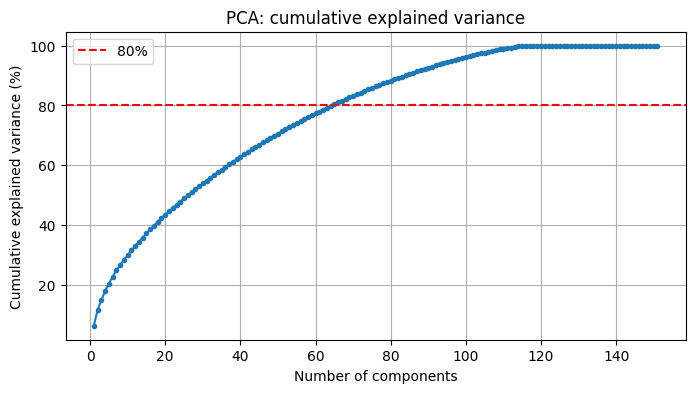

In [89]:
pca_full = PCA()
pca_full.fit(df_scaled)
explained = pca_full.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

print(f"Component 1 keeps: {explained[0]:.1f}%")
print(f"Component 2 keeps: {explained[1]:.1f}%")
print(f"First 2 components together: {cumulative[1]:.1f}%")
print(f"Components needed for 80%: {np.argmax(cumulative >= 80) + 1}")

plt.figure(figsize=(8,4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker=".")
plt.axhline(80, color="red", linestyle="--", label="80%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA: cumulative explained variance")
plt.legend()
plt.grid(True)
plt.savefig(f"{figures_folder}/pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

The first two components explain only 11.5% of the variance (6.2% and 5.2%), and the curve rises gradually without a clear bend. This shows that the information is spread across many components, which is typical for survey data with many separate categorical answers. 65 components are needed to keep 80% of the variance. These 65 components will be used for clustering, which reduces the data from 151 to 65 dimensions while keeping most of the information. The first two components will only be used for visualisation.

### 5.2 PCA with 65 components

Shape after PCA: (1143, 65)
Information kept: 80.1%


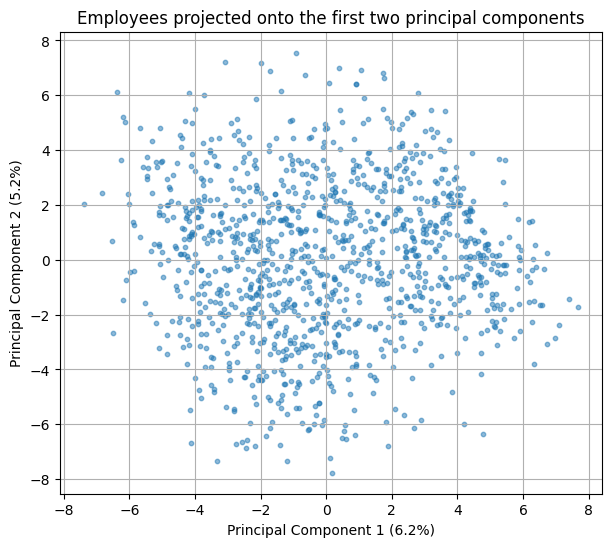

In [90]:
pca = PCA(n_components=65, random_state=42)
pca_data = pca.fit_transform(df_scaled)
print(f"Shape after PCA: {pca_data.shape}")
print(f"Information kept: {pca.explained_variance_ratio_.sum()*100:.1f}%")

plt.figure(figsize=(7,6))
plt.scatter(pca_data[:,0], pca_data[:,1], s=10, alpha=0.5)
plt.xlabel("Principal Component 1 (6.2%)")
plt.ylabel("Principal Component 2 (5.2%)")
plt.title("Employees projected onto the first two principal components")
plt.grid(True)
plt.savefig(f"{figures_folder}/pca_2d_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

The 2D scatter plot of the first two principal components shows one large cloud without clearly separated groups. Since these two components only contain 11.5% of the variance, differences between groups may exist in the other dimensions. It also suggests that employee groups in this survey are likely to overlap rather than being sharply separated, which should be considered when interpreting the clusters. The plot will be used again after clustering, with each employee coloured by their cluster.

### 5.3 Comparison with MDS

Shape after MDS: (1143, 2)


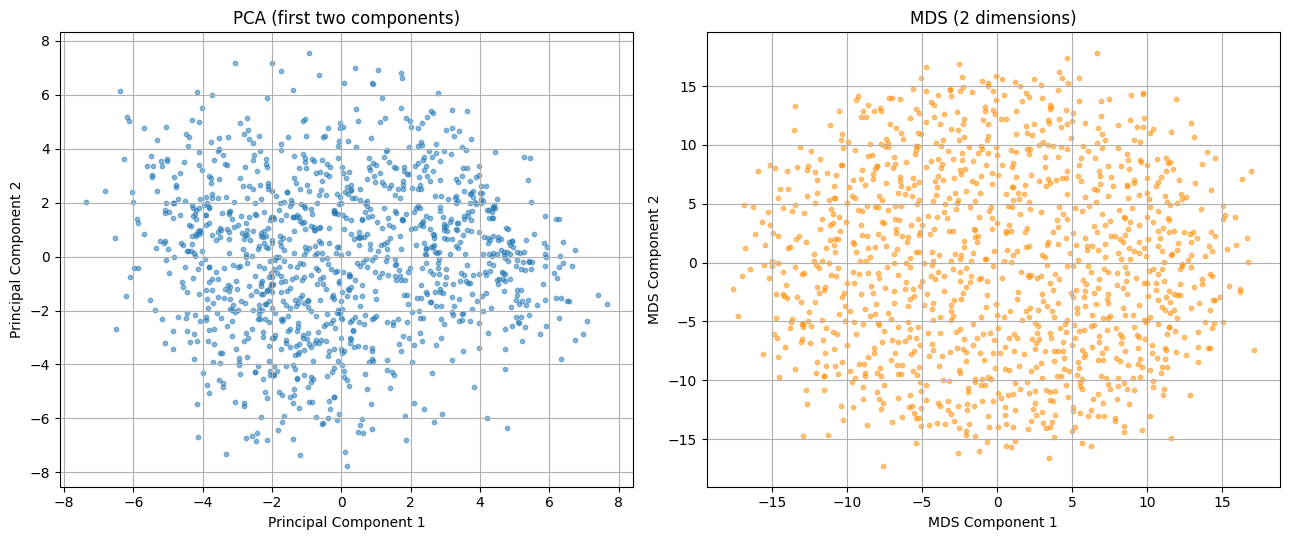

In [91]:
from sklearn.manifold import MDS
mds = MDS(n_components=2, random_state=42, n_init=1)
mds_data = mds.fit_transform(df_scaled)
print(f"Shape after MDS: {mds_data.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(pca_data[:,0], pca_data[:,1], s=10, alpha=0.5)
axes[0].set_title("PCA (first two components)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(True)

axes[1].scatter(mds_data[:,0], mds_data[:,1], s=10, alpha=0.5, color ="darkorange")
axes[1].set_title("MDS (2 dimensions)")
axes[1].set_xlabel("MDS Component 1")
axes[1].set_ylabel("MDS Component 2")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{figures_folder}/pca_vs_mds.png", dpi=150, bbox_inches="tight")
plt.show()

Metric MDS was applied as a second dimensionality reduction method. It places employees in 2D so that their original distances are preserved as well as possible. Like PCA, MDS shows one large cloud without clearly separated groups. Because two different methods lead to the same picture, this is a property of the data rather than of a single method. MDS spreads the points more evenly than PCA, which is typical for high-dimensional data, where most distances between respondents are similar. PCA is used for clustering because, unlike MDS, it can reduce the data to 65 dimensions while keeping 80% of the variance.

### 5.4 Summary of dimensionality reduction
PCA reduced the 151 columns to 65 components that keep 80% of the variance. Both PCA and MDS show one continuous cloud without clear gaps, suggesting that the clusters found in the next step will be overlapping employee types rather than strictly separated groups.

## Step 6: Clustering

### 6.1 Choosing the number of clusters

k=2: inertia=130068, silhouette=0.057
k=3: inertia=125505, silhouette=0.053
k=4: inertia=122758, silhouette=0.047
k=5: inertia=120450, silhouette=0.046
k=6: inertia=118345, silhouette=0.042
k=7: inertia=116456, silhouette=0.043
k=8: inertia=114834, silhouette=0.043
k=9: inertia=113742, silhouette=0.042
k=10: inertia=112491, silhouette=0.043


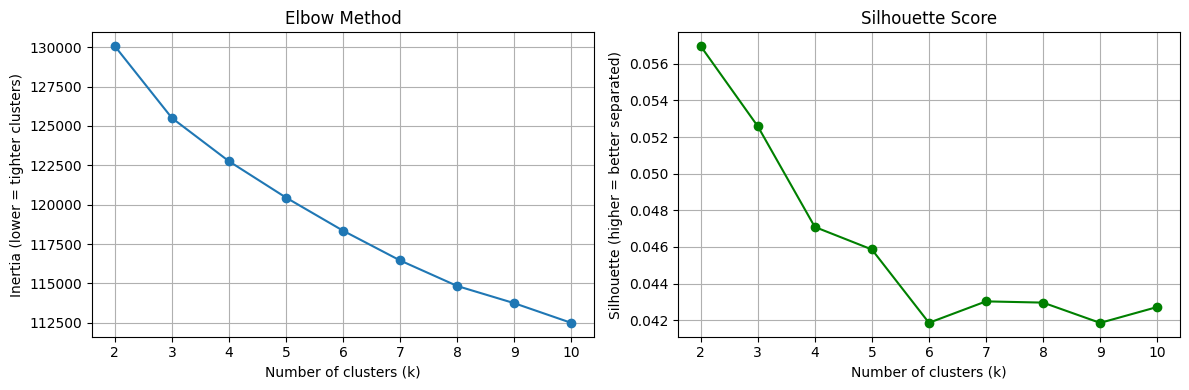

In [92]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
k_values = range(2,11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pca_data)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(pca_data, labels))
    print(f"k={k}: inertia={kmeans.inertia_:.0f}, silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (lower = tighter clusters)")
axes[0].grid(True)

axes[1].plot(k_values, silhouettes, marker="o",color ="green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette (higher = better separated)")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{figures_folder}/elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()




The elbow curve decreases steadily without a sharp bend; the largest improvement is from 2 to 3 clusters. The silhouette score is highest for k = 2 (0.057) and k = 3 (0.053) and drops from k = 4 onwards (0.047 and lower). k = 3 was chosen: it has almost the same silhouette score as k = 2, shows a slight bend in the elbow curve, and gives HR more differentiated groups than a simple split into two. All silhouette scores are very low, which confirms that the clusters overlap strongly. They should therefore be interpreted as typical employee profiles rather than clearly separated groups.

### 6.2 k-Means with k = 3

Silhouette score (k=3): 0.053
cluster
0    331
1    380
2    432
Name: count, dtype: int64


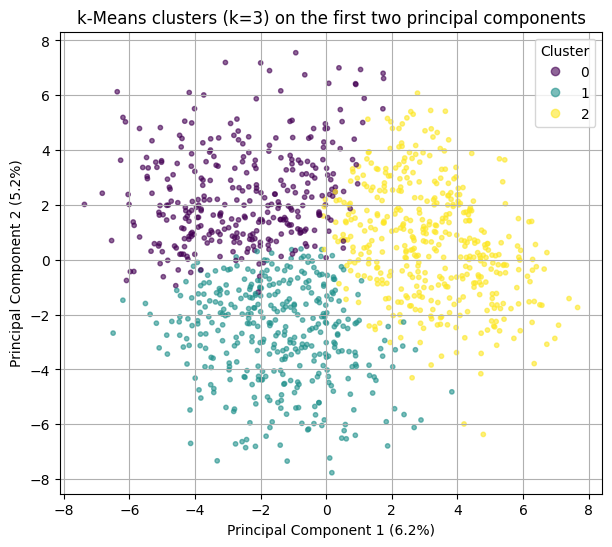

In [93]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(pca_data)

df_clean["cluster"] = cluster_labels

print(f"Silhouette score (k=3): {silhouette_score(pca_data, cluster_labels):.3f}")
print(df_clean["cluster"].value_counts().sort_index())

plt.figure(figsize=(7, 6))
scatter = plt.scatter(pca_data[:, 0], pca_data[:, 1], c=cluster_labels, cmap="viridis", s=10, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("Principal Component 1 (6.2%)")
plt.ylabel("Principal Component 2 (5.2%)")
plt.title("k-Means clusters (k=3) on the first two principal components")
plt.grid(True)
plt.savefig(f"{figures_folder}/kmeans_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

k-Means with 3 clusters divides the 1,143 employees into groups of 331, 380 and 432 respondents, with a silhouette score of 0.053. In the PCA plot, the three clusters occupy different regions of the cloud, but their borders touch without a clear gap. The clusters are therefore distinct but overlapping employee profiles. The cluster number of each employee was added to df_clean, so that the clusters can be described using the original answers in the next step. To make the results reproducible, a fixed random state (42) was used for PCA, MDS, k-Means and GMM.

### 6.3 Comparison with GMM

In [94]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

for shape in ["full", "spherical"]:
    gmm = GaussianMixture(n_components=3, covariance_type=shape, random_state=42, n_init=5)
    gmm_labels = gmm.fit_predict(pca_data)

    print(f"--- GMM ({shape}) ---")
    print(f"Cluster sizes: {np.bincount(gmm_labels)}")
    print(f"Silhouette score: {silhouette_score(pca_data, gmm_labels):.3f}")
    print(f"Agreement with k-Means (ARI): {adjusted_rand_score(cluster_labels, gmm_labels):.3f}")
    print(pd.crosstab(cluster_labels, gmm_labels, rownames=["k-Means"], colnames=["GMM"]))
    print()


--- GMM (full) ---
Cluster sizes: [345 356 442]
Silhouette score: 0.050
Agreement with k-Means (ARI): 0.806
GMM        0    1    2
k-Means               
0        306   10   15
1         28  341   11
2         11    5  416

--- GMM (spherical) ---
Cluster sizes: [333 382 428]
Silhouette score: 0.052
Agreement with k-Means (ARI): 0.927
GMM        0    1    2
k-Means               
0        320    4    7
1          7  373    0
2          6    5  421



To check the stability of the clusters, a Gaussian Mixture Model (GMM) with 3 components was applied as a second method. With spherical clusters, the GMM finds almost the same groups as k-Means (adjusted Rand index 0.927; only 29 of 1,143 employees are assigned differently, most likely those on the borders between groups) and a similar silhouette score (0.052). With full covariance, the GMM also agrees well in the final run (ARI 0.806, silhouette 0.050), but it was sensitive to small changes in the input: before the random state of the PCA was fixed, its agreement with k-Means varied strongly between runs (ARI between 0.25 and 0.81). This is because full covariance requires estimating a very large number of parameters in 65 dimensions, which is less reliable with only 1,143 respondents. Since two different algorithms consistently find the same three groups, the k-Means clusters are considered stable and are used for the interpretation.

## Step 7: Cluster profiles

### 7.1 Typical answers per cluster

In [95]:
profile_columns = [col for col in df_clean.columns if col not in ["cluster", "age", "work_position"]]

results = []
for col in profile_columns:
    overall_share = df_clean[col].value_counts(normalize=True)
    cluster_share = pd.crosstab(df_clean["cluster"], df_clean[col], normalize="index")
    for cluster in cluster_share.index:
        for answer in cluster_share.columns:
            results.append({
                "cluster": cluster,
                "question": col,
                "answer": answer,
                "in_cluster": cluster_share.loc[cluster, answer],
                "overall": overall_share[answer],
                "difference": cluster_share.loc[cluster, answer] - overall_share[answer],
            })

profiles = pd.DataFrame(results)


for cluster in sorted(df_clean["cluster"].unique()):
    print(f"\n===== Cluster {cluster} ({(df_clean['cluster'] == cluster).sum()} employees) =====")
    top = profiles[profiles["cluster"] == cluster].sort_values("difference", ascending=False).head(10)
    print(top[["question", "answer", "in_cluster", "overall"]].round(2).to_string(index=False))


===== Cluster 0 (331 employees) =====
                     question                               answer  in_cluster  overall
       comfortable_supervisor                                   No        0.61     0.29
        comfortable_coworkers                                   No        0.66     0.34
     mh_negative_consequences                                  Yes        0.51     0.19
    coworkers_view_negatively              Yes, I think they would        0.58     0.27
                  hurt_career                Yes, I think it would        0.67     0.39
             interview_mental                                   No        0.88     0.63
  employer_takes_mh_seriously                                   No        0.51     0.27
prev_mh_negative_consequences                     Yes, all of them        0.37     0.15
  prev_comfortable_supervisor No, at none of my previous employers        0.51     0.30
   prev_comfortable_coworkers No, at none of my previous employers        0.52   

The three clusters represent clearly different employee profiles. Cluster 0 (“fearful and unsupported”, 331 employees) is characterised by strong fear of stigma: most expect negative consequences from talking about mental health, would not feel comfortable talking to their supervisor or coworkers, and believe it would hurt their career. Cluster 1 (“affected but supported”, 380 employees) includes many employees with a diagnosed condition who have sought treatment, have mental health benefits and know their care options. Cluster 2 (“not personally affected”, 432 employees) consists mostly of employees who have never been diagnosed or treated and have no current mental health condition. A key finding is that clusters 0 and 1 both contain many affected employees, but differ strongly in how safe and supported they feel at work.

### 7.2 Key characteristics

{0: 'Fearful & unsupported', np.int32(2): 'Not personally affected', 1: 'Affected but supported'}
                         Diagnosed condition  Sought treatment  \
Fearful & unsupported                   69.0              74.0   
Affected but supported                  84.0              93.0   
Not personally affected                  4.0              13.0   

                         Has MH benefits  Comfortable with supervisor  \
Fearful & unsupported               35.0                         10.0   
Affected but supported              69.0                         57.0   
Not personally affected             34.0                         41.0   

                         Expects negative consequences  \
Fearful & unsupported                             51.0   
Affected but supported                             6.0   
Not personally affected                            7.0   

                         Thinks it would hurt career  
Fearful & unsupported                           67.0  
A

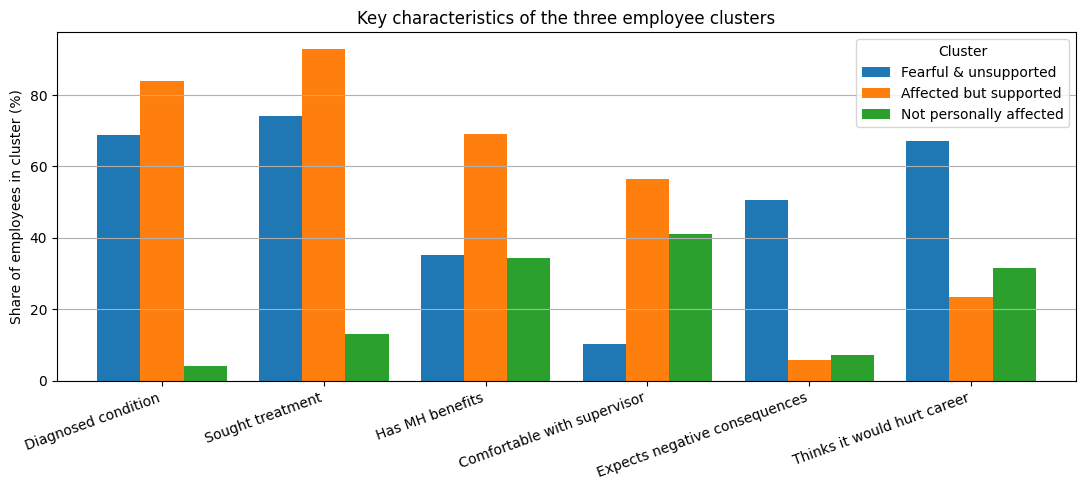

In [96]:

diagnosed_share = df_clean.groupby("cluster")["diagnosed_professional"].apply(lambda x: (x == "Yes").mean())
supervisor_share = df_clean.groupby("cluster")["comfortable_supervisor"].apply(lambda x: (x == "Yes").mean())

not_affected = diagnosed_share.idxmin()
affected = [c for c in diagnosed_share.index if c != not_affected]
fearful = min(affected, key=lambda c: supervisor_share[c])
supported = [c for c in affected if c != fearful][0]

cluster_names = {fearful: "Fearful & unsupported", not_affected: "Not personally affected", supported: "Affected but supported"}
print(cluster_names)


indicators = pd.DataFrame({
    "Diagnosed condition": df_clean.groupby("cluster")["diagnosed_professional"].apply(lambda x: (x == "Yes").mean()),
    "Sought treatment": df_clean.groupby("cluster")["sought_treatment"].mean(),
    "Has MH benefits": df_clean.groupby("cluster")["mh_benefits"].apply(lambda x: (x == "Yes").mean()),
    "Comfortable with supervisor": df_clean.groupby("cluster")["comfortable_supervisor"].apply(lambda x: (x == "Yes").mean()),
    "Expects negative consequences": df_clean.groupby("cluster")["mh_negative_consequences"].apply(lambda x: (x == "Yes").mean()),
    "Thinks it would hurt career": df_clean.groupby("cluster")["hurt_career"].apply(lambda x: (x == "Yes, I think it would").mean()),
}) * 100

indicators.index = [cluster_names[c] for c in indicators.index]
print(indicators.round(0))


indicators.T.plot(kind="bar", figsize=(11, 5), width=0.8)
plt.ylabel("Share of employees in cluster (%)")
plt.title("Key characteristics of the three employee clusters")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Cluster")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig(f"{figures_folder}/cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

The comparison of key indicators shows that the clusters “fearful and unsupported” and “affected but supported” both contain many employees with a diagnosed condition (69% and 84%) who have sought treatment (74% and 93%), and the main difference is their work environment. In the supported group, 69% have mental health benefits and 57% would feel comfortable talking to their supervisor, compared to only 35% and 10% in the fearful group. In addition, 51% of the fearful group expect negative consequences and 67% believe it would hurt their career, compared to 6% and 23% in the supported group. This suggests that the main difference is not the mental health condition itself, but workplace factors such as benefits, trust in supervisors and fear of stigma, which can be influenced by HR. Even in the “not personally affected” group, only 41% would feel comfortable talking to their supervisor, which indicates a general need to reduce stigma.

### 7.3 Background characteristics

In [97]:
print("Average age per cluster:")
print(df_clean.groupby("cluster")["age"].mean().round(1))


for col in ["gender", "company_size", "remote_work", "tech_company"]:
    print(f"\n--- {col} (% within each cluster) ---")
    print((pd.crosstab(df_clean["cluster"], df_clean[col], normalize="index") * 100).round(0))

Average age per cluster:
cluster
0    33.7
1    34.1
2    32.5
Name: age, dtype: float64

--- gender (% within each cluster) ---
gender   female  male  other  unknown
cluster                              
0          28.0  68.0    3.0      1.0
1          31.0  65.0    4.0      0.0
2          13.0  86.0    1.0      0.0

--- company_size (% within each cluster) ---
company_size  1-5  100-500  26-100  500-1000  6-25  More than 1000
cluster                                                           
0             7.0     21.0    25.0       4.0  18.0            25.0
1             4.0     25.0    25.0       9.0  14.0            23.0
2             5.0     19.0    26.0       8.0  22.0            20.0

--- remote_work (% within each cluster) ---
remote_work  Always  Never  Sometimes
cluster                              
0              15.0   34.0       51.0
1              22.0   21.0       57.0
2              20.0   29.0       51.0

--- tech_company (% within each cluster) ---
tech_company   0.0 

The background characteristics of the three clusters are largely similar: the average age (32.5 to 34.1 years), company size and the share working at tech companies differ only slightly. The main differences are gender, with the “not personally affected” group being 86% male compared to 65–68% in the other groups, and remote work, where the fearful group works on-site more often (34% never remote, compared to 21% in the supported group). Since the clusters cannot be clearly identified by demographics, HR measures should focus on workplace culture and support across the whole organisation rather than on specific employee groups.

### 7.4 Summary of clustering and cluster profiles

 k-Means identified three employee profiles, which were confirmed by a Gaussian Mixture Model. The “fearful and unsupported” group (331 employees) is often affected by mental health conditions but distrusts the workplace and fears negative consequences. The “affected but supported” group (380 employees) is similarly affected but has benefits, knows its options and trusts supervisors. The “not personally affected” group (432 employees) has little personal experience with mental health conditions. The key difference between the two affected groups lies in workplace factors that HR can influence: benefits, supervisor trust and stigma.